# Single-frequency CMB observation check
Compare one reproducible full-sky realization with analytical spectra, with and without polarization rotation. Scalar noise and beam inputs exercise the single-channel interface. Both cases use the same `idx` (same underlying CMB and noise).

We plot $D_\ell=\ell(\ell+1)C_\ell/(2\pi)$, with no beam deconvolution or noise subtraction. Theory includes the beam and auto-spectrum noise bias. Binning reduces realization scatter; error bars show full-sky Gaussian sample + noise uncertainty for **one realization**. Analysis stops at $2N_{\rm side}$ to avoid the highest HEALPix multipoles.

In [1]:
%matplotlib inline
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
import sim

plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.2})

# Change these scalar parameters and rerun the notebook.
nside = 256
nlevp = 10.0       # uK-arcmin
fwhm = 30.0       # arcmin
alpha_deg = 2.0   # degrees; deliberately visible rotation
idx = 0
lmax = min(2 * nside, 6000)
bin_width = 20

obs_unrotated = sim.CMBobs(nside, nlevp, fwhm, alpha=None)
obs_rotated = sim.CMBobs(nside, nlevp, fwhm, alpha=alpha_deg)

# observedmap returns (1, 3, npix); select the single frequency.
map_unrotated = obs_unrotated.observedmap(idx)[0]
map_rotated = obs_rotated.observedmap(idx)[0]
assert map_unrotated.shape == (3, hp.nside2npix(nside))
assert np.isfinite(map_unrotated).all() and np.isfinite(map_rotated).all()
np.testing.assert_array_equal(map_unrotated[0], map_rotated[0])

# anafast ordering: TT, EE, BB, TE, EB, TB.
cl_unrotated = hp.anafast(map_unrotated, lmax=lmax, pol=True)
cl_rotated = hp.anafast(map_rotated, lmax=lmax, pol=True)
print(f'nside={nside}, nlevp={nlevp:g} uK-arcmin, fwhm={fwhm:g} arcmin, idx={idx}')
print(f'Rotation: None versus {alpha_deg:g} degrees; analysis lmax={lmax}')

nside=256, nlevp=10 uK-arcmin, fwhm=30 arcmin, idx=0
Rotation: None versus 2 degrees; analysis lmax=512


## Analytical spectra
For the class convention $(Q+iU)'=e^{2i\alpha}(Q+iU)$, let $c=\cos(2\alpha)$ and $s=\sin(2\alpha)$. With intrinsic $EB=TB=0$,

$$C_\ell^{EE,\alpha}=c^2C_\ell^{EE}+s^2C_\ell^{BB},\quad
C_\ell^{BB,\alpha}=s^2C_\ell^{EE}+c^2C_\ell^{BB},$$
$$C_\ell^{EB,\alpha}=\tfrac12\sin(4\alpha)(C_\ell^{EE}-C_\ell^{BB}),\quad
C_\ell^{TE,\alpha}=cC_\ell^{TE},\quad C_\ell^{TB,\alpha}=sC_\ell^{TE}.$$

The observed prediction is $C_\ell^{XY,\mathrm{obs}}=b_\ell^X b_\ell^Y C_\ell^{XY,\alpha}+N_\ell^{XY}$, using polarized beams matching `hp.smoothing`. For independent white noise, $N^{EE}=N^{BB}=(n_{\rm lev,p}\pi/(180\times60))^2$, $N^{TT}=N^{EE}/2$, and cross-noise expectations vanish. Noise is added **after** smoothing, so its spectrum is not beam-suppressed. No pixel window is applied by this simulator.

References: [healpy beam convention](https://healpy.readthedocs.io/en/latest/generated/healpy.sphtfunc.gauss_beam.html) and [anafast output ordering](https://healpy.readthedocs.io/en/latest/generated/healpy.sphtfunc.anafast.html).

In [2]:
ell = np.arange(lmax + 1)
dl_factor = ell * (ell + 1) / (2 * np.pi)
tt, ee, bb, te = sim.get_lensed_cmb_spectra(lmax).T
beam = hp.gauss_beam(np.deg2rad(fwhm / 60), lmax=lmax, pol=True)
bt, be, bb_beam = beam[:, :3].T
noise_p = (nlevp * np.pi / (180 * 60))**2

def analytical_cls(angle_deg):
    c, s = np.cos(2 * np.deg2rad(angle_deg)), np.sin(2 * np.deg2rad(angle_deg))
    return np.array([
        bt**2 * tt + noise_p / 2,
        be**2 * (c*c * ee + s*s * bb) + noise_p,
        bb_beam**2 * (s*s * ee + c*c * bb) + noise_p,
        bt * be * c * te,
        be * bb_beam * c * s * (ee - bb),
        bt * bb_beam * s * te,
    ])

theory_unrotated = analytical_cls(0)
theory_rotated = analytical_cls(alpha_deg)

# Identical (2l+1)-weighted binning for simulations and theory.
edges = np.append(np.arange(2, lmax + 1, bin_width), lmax + 1)
bins = [np.arange(lo, hi) for lo, hi in zip(edges[:-1], edges[1:])]
weights = [(2 * ell[b] + 1) / np.sum(2 * ell[b] + 1) for b in bins]
ell_binned = np.array([np.sum(w * ell[b]) for b, w in zip(bins, weights)])

def bin_dl(cls):
    return np.array([np.sum(cls[..., b] * dl_factor[b] * w, axis=-1)
                     for b, w in zip(bins, weights)]).T

def bandpower_sigma(theory):
    # Var(C_l^XY) = [(C_l^XY)^2 + C_l^XX C_l^YY] / (2l+1).
    pairs = [(0, 0), (1, 1), (2, 2), (0, 1), (1, 2), (0, 2)]
    variance = np.array([(theory[k]**2 + theory[x] * theory[y]) / (2 * ell + 1)
                         for k, (x, y) in enumerate(pairs)])
    return np.sqrt(np.array([
        np.sum(variance[:, b] * (dl_factor[b] * w)**2, axis=-1)
        for b, w in zip(bins, weights)
    ]).T)

cases = [
    ('No rotation', cl_unrotated, theory_unrotated, '#2563eb'),
    (f'Rotation: {alpha_deg:g} deg', cl_rotated, theory_rotated, '#d97706'),
]

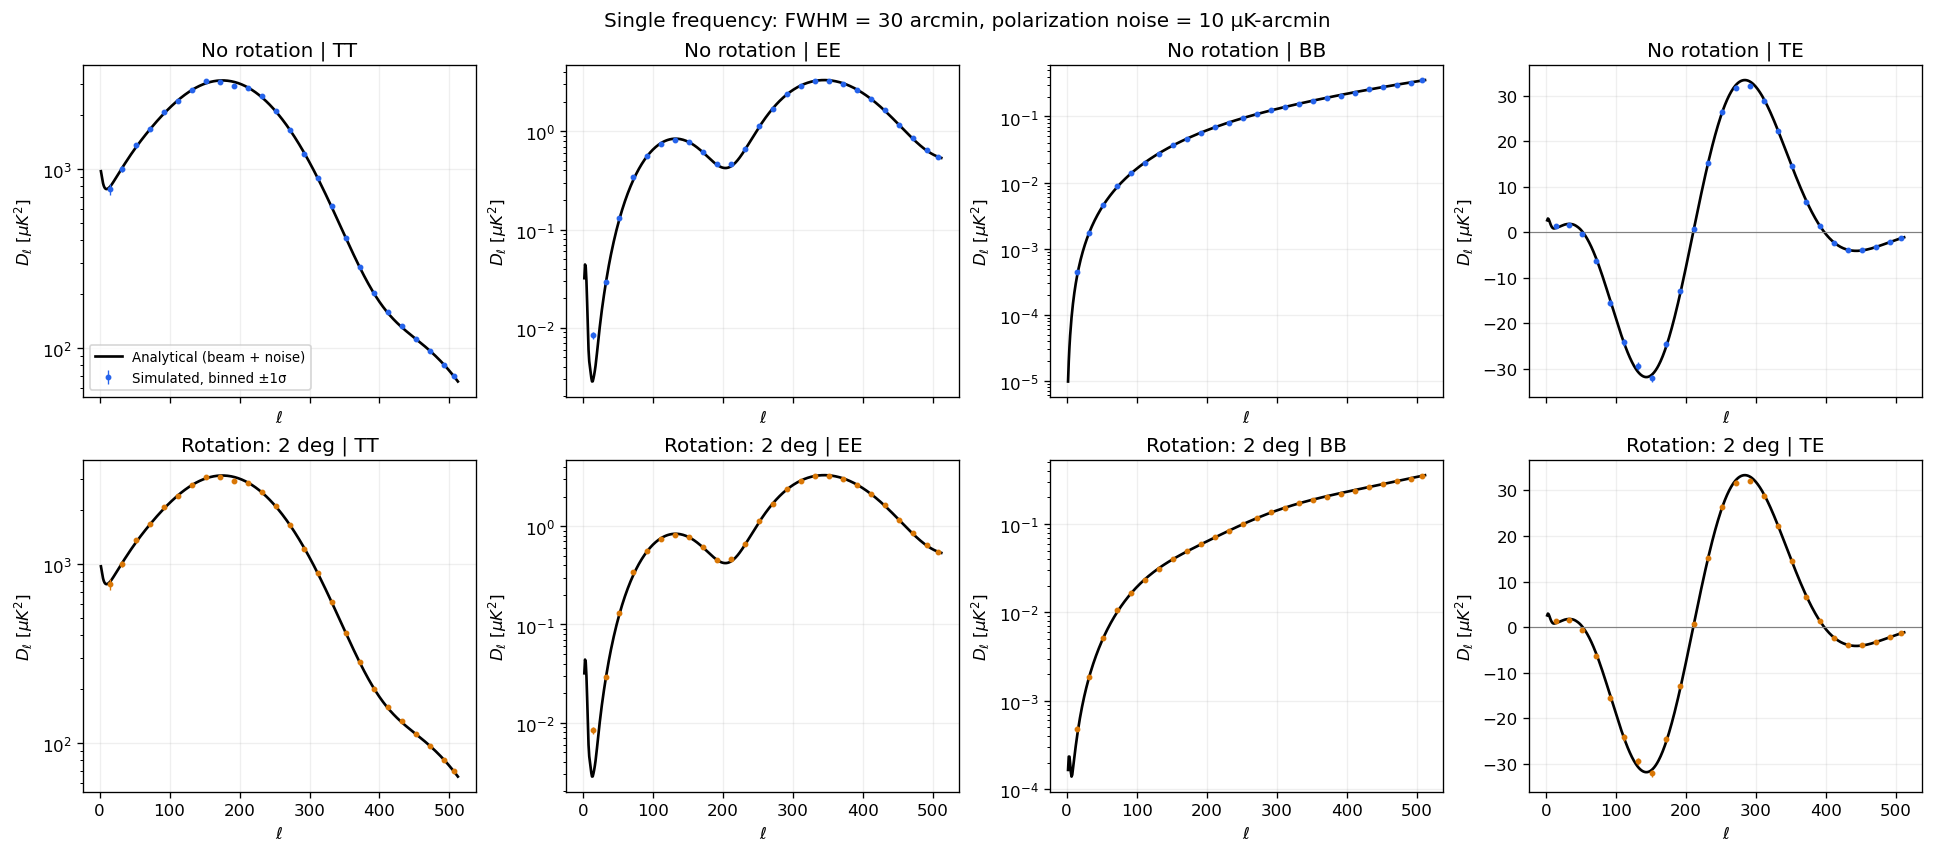

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True, layout='constrained')
for row, (label, measured, theory, color) in enumerate(cases):
    measured_b, sigma = bin_dl(measured), bandpower_sigma(theory)
    for k, name in enumerate(['TT', 'EE', 'BB', 'TE']):
        ax = axes[row, k]
        ax.plot(ell[2:], (dl_factor * theory[k])[2:], color='black', lw=1.6,
                label='Analytical (beam + noise)')
        ax.errorbar(ell_binned, measured_b[k], yerr=sigma[k], fmt='.',
                    ms=5, color=color, elinewidth=0.8, label='Simulated, binned ±1σ')
        ax.set_title(f'{label} | {name}')
        ax.set_ylabel(r'$D_\ell\ [\mu K^2]$')
        ax.set_xlabel(r'$\ell$')
        if k < 3:
            ax.set_yscale('log')
        else:
            ax.axhline(0, color='gray', lw=0.7)
axes[0, 0].legend(fontsize=8)
fig.suptitle(f'Single frequency: FWHM = {fwhm:g} arcmin, polarization noise = {nlevp:g} µK-arcmin')
plt.show()

## EB: rotation signal and null test
The unrotated expectation is zero. A single sky still has fluctuating EB. Rotation produces
$$C_\ell^{EB,\mathrm{obs}}=b_\ell^E b_\ell^B\,\frac{\sin(4\alpha)}{2}(C_\ell^{EE}-C_\ell^{BB}).$$
There is no additive EB noise bias, but noise contributes to its uncertainty. Lower panels compare **identically binned** simulated and analytical spectra, normalized by the predicted uncertainty. The two cases share a sky and noise, so their residuals are correlated.

No rotation: EB chi² / number of bins = 19.6 / 26
Rotation: 2 deg: EB chi² / number of bins = 21.6 / 26


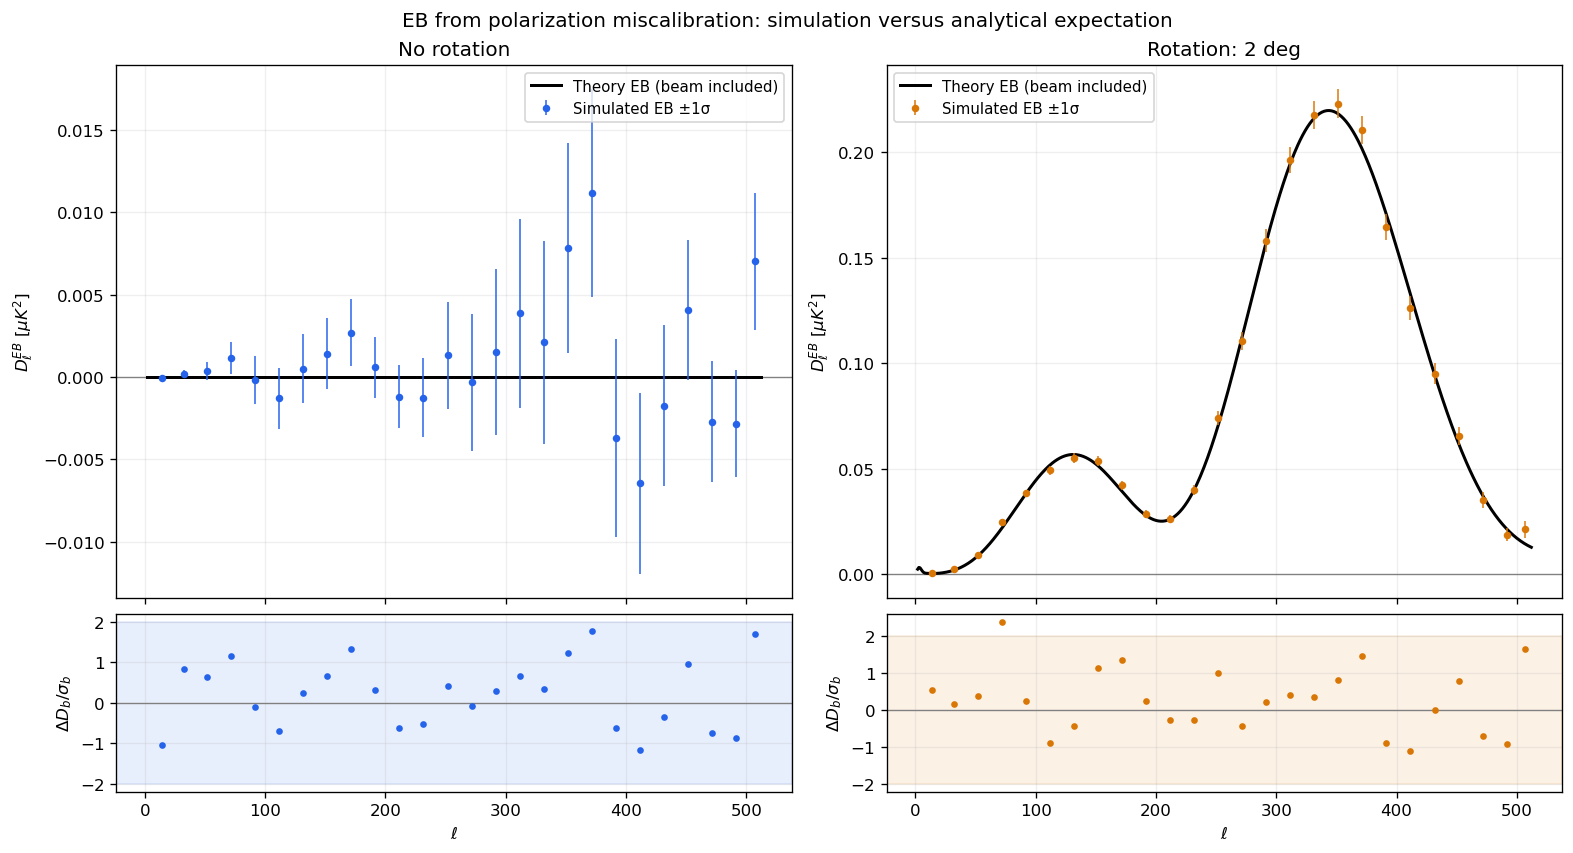

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1]}, layout='constrained')
for col, (label, measured, theory, color) in enumerate(cases):
    measured_b, theory_b = bin_dl(measured), bin_dl(theory)
    sigma = bandpower_sigma(theory)[4]
    ax = axes[0, col]
    ax.axhline(0, color='gray', lw=0.8)
    ax.plot(ell[2:], (dl_factor * theory[4])[2:], color='black', lw=1.8,
            label='Theory EB (beam included)')
    ax.errorbar(ell_binned, measured_b[4], yerr=sigma, fmt='o', ms=3.5,
                color=color, elinewidth=0.9, label='Simulated EB ±1σ')
    ax.set(title=label, ylabel=r'$D_\ell^{EB}\ [\mu K^2]$')
    ax.legend(fontsize=9)
    residual = (measured_b[4] - theory_b[4]) / sigma
    axes[1, col].axhspan(-2, 2, color=color, alpha=0.1)
    axes[1, col].axhline(0, color='gray', lw=0.8)
    axes[1, col].plot(ell_binned, residual, '.', color=color)
    axes[1, col].set(xlabel=r'$\ell$', ylabel=r'$\Delta D_b/\sigma_b$')
    print(f'{label}: EB chi² / number of bins = {np.sum(residual**2):.1f} / {len(residual)}')
fig.suptitle('EB from polarization miscalibration: simulation versus analytical expectation')
plt.show()